# Classificação de Espécies de Corujas com Redes Neurais

## 1. Introdução

A distinção visual entre aves exige a análise de traços morfológicos detalhados, tais como as texturas da plumagem, as proporções do bico e os padrões faciais. Este projeto explora a aplicação de modelos de Visão Computacional na identificação automatizada de corujas (família *Strigidae*), empregando um repositório público de imagens para treinar o algoritmo.

A tarefa consiste numa **classificação multiclasse**, em que o sistema processa tensores de píxeis como entrada e deve inferir a qual das 20 espécies catalogadas a fotografia pertence. A arquitetura da rede será desenhada para extrair os recursos espaciais intrínsecos às imagens, analisando simultaneamente como a introdução de técnicas de regularização afeta a aprendizagem e evita a memorização excessiva dos dados.

**Objetivos do projeto:** mensurar a eficácia preditiva do modelo, investigar quais as classes que geram maior confusão estatística e debater a viabilidade de embarcar esta solução em projetos de Engenharia, como sistemas de monitoramento não intrusivo para a conservação da fauna.

Para reproduzir o experimento, execute as células sequencialmente. O primeiro bloco prepara o ambiente de desenvolvimento instalando as dependências de software. Os gráficos e indicadores já visíveis representam o estado da última execução validada; caso decida reparametrizar a rede, lembre-se de reavaliar os textos de discussão.

## 2. Bibliotecas

Utilizamos `NumPy` e `Pandas` para trabalhar com os dados tabulares, `Matplotlib` para os gráficos, `Scikit-learn` para as métricas de avaliação e `TensorFlow/Keras` para o carregamento de imagens e construção da rede neuronal. As bibliotecas são instaladas e importadas na célula a seguir.

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn tensorflow

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "| Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

Python: 3.13.16
NumPy: 2.4.6 | Pandas: 2.2.3
Scikit-learn: 1.6.1
TensorFlow: 2.21.0
Matplotlib: 3.10.0


## 3. Base de dados

Utilizamos uma base de dados de imagens contendo 20 espécies de corujas da família *Strigidae*. Ao contrário de dados tabulares (CSV), as imagens estão organizadas em diretórios, onde o nome de cada subpasta corresponde ao rótulo (label) da espécie.

Na célula a seguir, definimos o caminho para os dados (previamente extraídos para a pasta `/content/imgs`) e contabilizamos a quantidade de exemplos disponíveis por espécie para verificar se a base está balanceada.

In [2]:
!gdown --id 1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is -O imgs.zip

!unzip -q imgs.zip -d /content/

!rm imgs.zip

print("Download e descompactação concluídos com sucesso!")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is
From (redirected): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is&confirm=t&uuid=b3e8c889-45ac-4700-97d6-e73dd67f49a4
To: /content/imgs.zip
100% 985M/985M [00:31<00:00, 31.1MB/s]
Download e descompactação concluídos com sucesso!


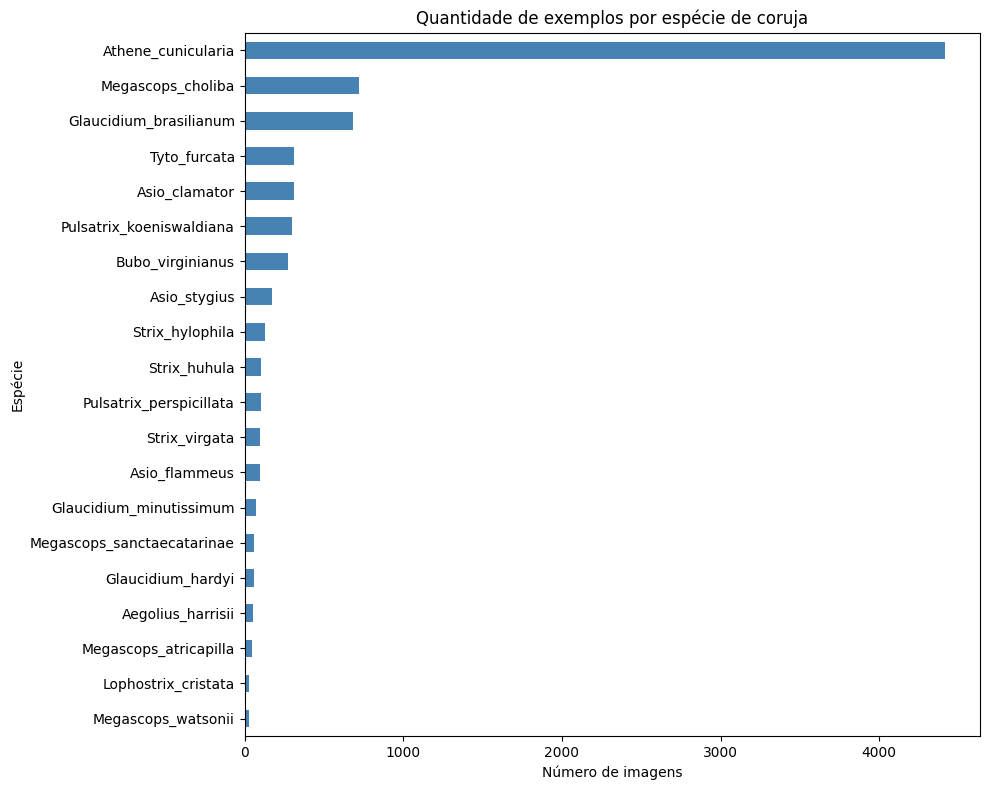

Total de classes (espécies): 20
Total de imagens na base: 8067


In [3]:
import os

data_dir = '/content/imgs'

contagem = {}
if os.path.exists(data_dir):
    classes = sorted(os.listdir(data_dir))
    for cl in classes:
        caminho_classe = os.path.join(data_dir, cl)
        if os.path.isdir(caminho_classe):
            contagem[cl] = len(os.listdir(caminho_classe))

contagem_serie = pd.Series(contagem).sort_values()

contagem_serie.plot.barh(figsize=(10, 8), color="steelblue")
plt.title("Quantidade de exemplos por espécie de coruja")
plt.xlabel("Número de imagens")
plt.ylabel("Espécie")
plt.tight_layout()
plt.show()

print("Total de classes (espécies):", len(contagem_serie))
print("Total de imagens na base:", contagem_serie.sum())

In [4]:
print("Quantidade exata de imagens por espécie:")
print("-" * 50)

for especie, quantidade in contagem_serie.items():
    print(f"{especie}: {quantidade} imagens")

print("-" * 50)
print(f"Total geral: {contagem_serie.sum()} imagens")

Quantidade exata de imagens por espécie:
--------------------------------------------------
Megascops_watsonii: 26 imagens
Lophostrix_cristata: 27 imagens
Megascops_atricapilla: 44 imagens
Aegolius_harrisii: 55 imagens
Glaucidium_hardyi: 57 imagens
Megascops_sanctaecatarinae: 58 imagens
Glaucidium_minutissimum: 74 imagens
Asio_flammeus: 96 imagens
Strix_virgata: 96 imagens
Pulsatrix_perspicillata: 105 imagens
Strix_huhula: 106 imagens
Strix_hylophila: 131 imagens
Asio_stygius: 175 imagens
Bubo_virginianus: 271 imagens
Pulsatrix_koeniswaldiana: 300 imagens
Asio_clamator: 310 imagens
Tyto_furcata: 312 imagens
Glaucidium_brasilianum: 686 imagens
Megascops_choliba: 723 imagens
Athene_cunicularia: 4415 imagens
--------------------------------------------------
Total geral: 8067 imagens


**Análise da Distribuição dos Dados:**
A extração exata das quantidades confirma que o conjunto de dados possui um desbalanceamento significativo. Algumas espécies (como a *Athene_cunicularia*) dominam a base de dados com centenas de amostras, enquanto outras espécies apresentam um volume muito menor. Este desbalanceamento será um fator crítico a ser considerado na análise de desempenho do modelo, pois redes neuronais tendem a enviesar os seus resultados para as classes maioritárias.

## 4. Metodologia e preparação

### 4.1. Carregamento e divisão dos dados

Para o processamento de imagens, utilizamos a função `image_dataset_from_directory` do Keras. Ela carrega as imagens, converte os rótulos dinamicamente a partir dos nomes das pastas e divide os dados em lotes (*batches*).

Neste passo, todas as imagens são redimensionadas para 224x224 píxeis (padrão comum em Visão Computacional). Separamos **80% dos dados para treino** e **20% para teste/validação**. O uso da semente (`seed=42`) garante que a divisão seja exatamente a mesma em futuras execuções.

In [5]:
tamanho_imagem = (224, 224)
tamanho_lote = 32

print("Conjunto de Treino:")
dataset_treino = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=tamanho_imagem,
    batch_size=tamanho_lote
)

print("\nConjunto de Teste/Validação:")
dataset_validacao = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=tamanho_imagem,
    batch_size=tamanho_lote
)

nomes_das_classes = dataset_treino.class_names

AUTOTUNE = tf.data.AUTOTUNE
dataset_treino = dataset_treino.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
dataset_validacao = dataset_validacao.cache().prefetch(buffer_size=AUTOTUNE)

Conjunto de Treino:
Found 8067 files belonging to 20 classes.
Using 6454 files for training.

Conjunto de Teste/Validação:
Found 8067 files belonging to 20 classes.
Using 1613 files for validation.


### 4.2. Padronização (Normalização dos Píxeis)

Diferente do `StandardScaler` usado em dados tabulares, as imagens possuem píxeis com valores de 0 a 255. Para redes neuronais, é fundamental normalizar estes valores para um intervalo de 0 a 1.

Isso evita que as magnitudes dos píxeis dominem as atualizações dos pesos durante o treino. Em vez de transformar o *dataset* agora, iremos incorporar uma camada `Rescaling(1./255)` diretamente como a primeira etapa dentro da arquitetura dos nossos modelos, garantindo que qualquer nova imagem siga automaticamente o mesmo pré-processamento.

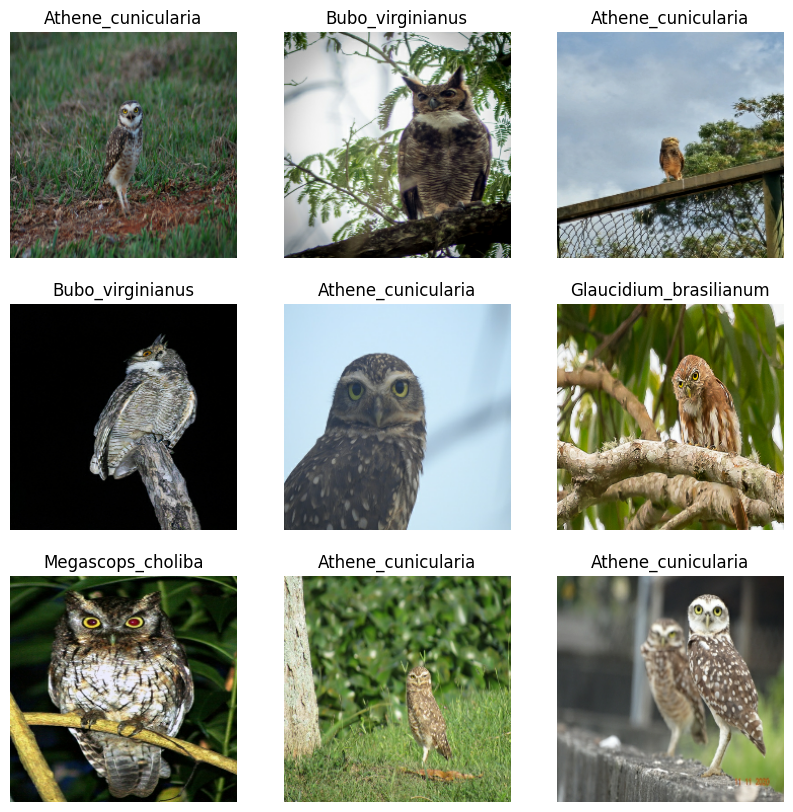

In [6]:

plt.figure(figsize=(10, 10))
for imagens, rotulos in dataset_treino.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype("uint8"))
        plt.title(nomes_das_classes[rotulos[i]])
        plt.axis("off")
plt.show()


## 5. Implementação da Rede Neural Convolucional (CNN)

Para classificar as imagens, utilizaremos uma Rede Neural Convolucional (CNN). Ao contrário de redes mais simples que achatam a imagem imediatamente, a CNN utiliza camadas convolucionais (`Conv2D`) e de agrupamento (`MaxPooling2D`) para extrair características espaciais bidimensionais, como formatos de bicos, olhos e texturas das penas.

Para garantir que o modelo consiga generalizar bem e não sofra de *overfitting* (memorização dos dados de treino), aplicamos três técnicas integradas:
1. **Data Augmentation:** Rotações, zoom e inversões horizontais aplicadas aleatoriamente durante o treino.
2. **Dropout:** Desativação aleatória de 50% dos neurónios na camada final de classificação.
3. **Early Stopping:** O Keras monitorizará a perda na validação (`val_loss`) e interromperá o treino caso não haja melhorias após 3 épocas consecutivas, restaurando os melhores pesos encontrados.

In [7]:
from tensorflow.keras import layers, models, callbacks

num_classes = len(nomes_das_classes)

modelo = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

parada_antecipada = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

print("Iniciando o treinamento da CNN...")
history = modelo.fit(
    dataset_treino,
    validation_data=dataset_validacao,
    epochs=15,
    callbacks=[parada_antecipada]
)

Iniciando o treinamento da CNN...
Epoch 1/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.5493 - loss: 1.8112 - val_accuracy: 0.5772 - val_loss: 1.5268
Epoch 2/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5564 - loss: 1.6412 - val_accuracy: 0.5666 - val_loss: 1.5752
Epoch 3/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5734 - loss: 1.5723 - val_accuracy: 0.5952 - val_loss: 1.4279
Epoch 4/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5764 - loss: 1.5305 - val_accuracy: 0.6001 - val_loss: 1.3961
Epoch 5/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5899 - loss: 1.4926 - val_accuracy: 0.6069 - val_loss: 1.3952
Epoch 6/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5916 - loss: 1.4644 - val_accuracy: 0.6063 - val_loss: 1.3870
Epoch 7/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5941 - loss: 1.4451 - val_accuracy: 0.5927 - val_loss: 1.4184
Epoch 8/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accurac

## 6. Avaliação e Análise dos Resultados

Para avaliar o desempenho do nosso modelo, utilizamos duas abordagens visuais fundamentais:

1. **Curvas de Aprendizagem:** Comparamos a evolução da acurácia e do erro (loss) entre o conjunto de treino e o conjunto de validação ao longo das épocas. Isto permite-nos verificar se o modelo está a aprender corretamente ou se está a sofrer de *overfitting* (quando a linha de treino continua a melhorar, mas a de validação estagna ou piora).
2. **Matriz de Confusão:** Avaliamos o desempenho detalhado cruzando as espécies reais com as previsões do modelo. A diagonal principal mostra os acertos, enquanto os valores fora da diagonal indicam quais as espécies de corujas que a rede está a confundir mais frequentemente.

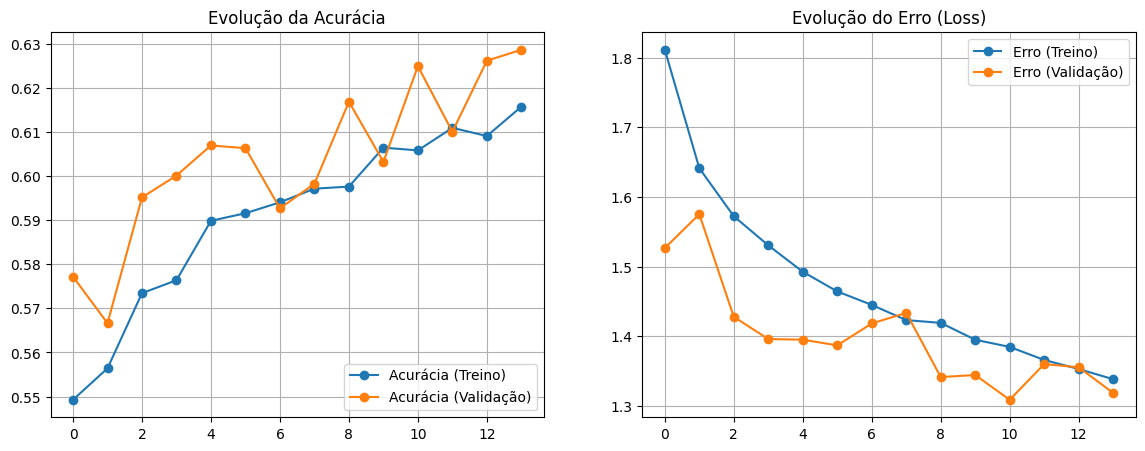

In [8]:

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epocas_treinadas = range(len(acc))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epocas_treinadas, acc, label='Acurácia (Treino)', marker='o')
plt.plot(epocas_treinadas, val_acc, label='Acurácia (Validação)', marker='o')
plt.legend(loc='lower right')
plt.title('Evolução da Acurácia')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epocas_treinadas, loss, label='Erro (Treino)', marker='o')
plt.plot(epocas_treinadas, val_loss, label='Erro (Validação)', marker='o')
plt.legend(loc='upper right')
plt.title('Evolução do Erro (Loss)')
plt.grid(True)

plt.show()

Avaliação da V1 no conjunto de validação (split 80/20)...

Métricas da V1 na validação:
  loss_val: 1.3089
  acuracia: 0.6249
  acuracia_balanceada: 0.1081
  precisao_macro: 0.1034
  recall_macro: 0.1081
  f1_macro: 0.0955
  top3: 0.7712

Relatório por espécie:
                            precision    recall  f1-score   support

         Aegolius_harrisii      0.000     0.000     0.000         7
             Asio_clamator      0.167     0.019     0.033        54
             Asio_flammeus      0.000     0.000     0.000        12
              Asio_stygius      0.000     0.000     0.000        33
        Athene_cunicularia      0.767     0.961     0.853       892
          Bubo_virginianus      0.171     0.091     0.119        66
    Glaucidium_brasilianum      0.474     0.580     0.522       143
         Glaucidium_hardyi      0.000     0.000     0.000        12
   Glaucidium_minutissimum      0.000     0.000     0.000         9
       Lophostrix_cristata      0.000     0.000     0.000

,Classe,Suporte,Recall
0,Aegolius_harrisii,7,0.000
2,Asio_flammeus,12,0.000
3,Asio_stygius,33,0.000
7,Glaucidium_hardyi,12,0.000
12,Megascops_sanctaecatarinae,15,0.000
10,Megascops_atricapilla,11,0.000
9,Lophostrix_cristata,4,0.000
8,Glaucidium_minutissimum,9,0.000
14,Pulsatrix_koeniswaldiana,76,0.000
13,Megascops_watsonii,8,0.000


Classes com recall zero: ['Aegolius_harrisii', 'Asio_flammeus', 'Asio_stygius', 'Glaucidium_hardyi', 'Megascops_sanctaecatarinae', 'Megascops_atricapilla', 'Lophostrix_cristata', 'Glaucidium_minutissimum', 'Pulsatrix_koeniswaldiana', 'Megascops_watsonii', 'Pulsatrix_perspicillata', 'Strix_huhula', 'Strix_hylophila', 'Strix_virgata']
Classes com recall < 10%: ['Aegolius_harrisii', 'Asio_flammeus', 'Asio_stygius', 'Glaucidium_hardyi', 'Megascops_sanctaecatarinae', 'Megascops_atricapilla', 'Lophostrix_cristata', 'Glaucidium_minutissimum', 'Pulsatrix_koeniswaldiana', 'Megascops_watsonii', 'Pulsatrix_perspicillata', 'Strix_huhula', 'Strix_hylophila', 'Strix_virgata', 'Asio_clamator', 'Tyto_furcata', 'Bubo_virginianus']


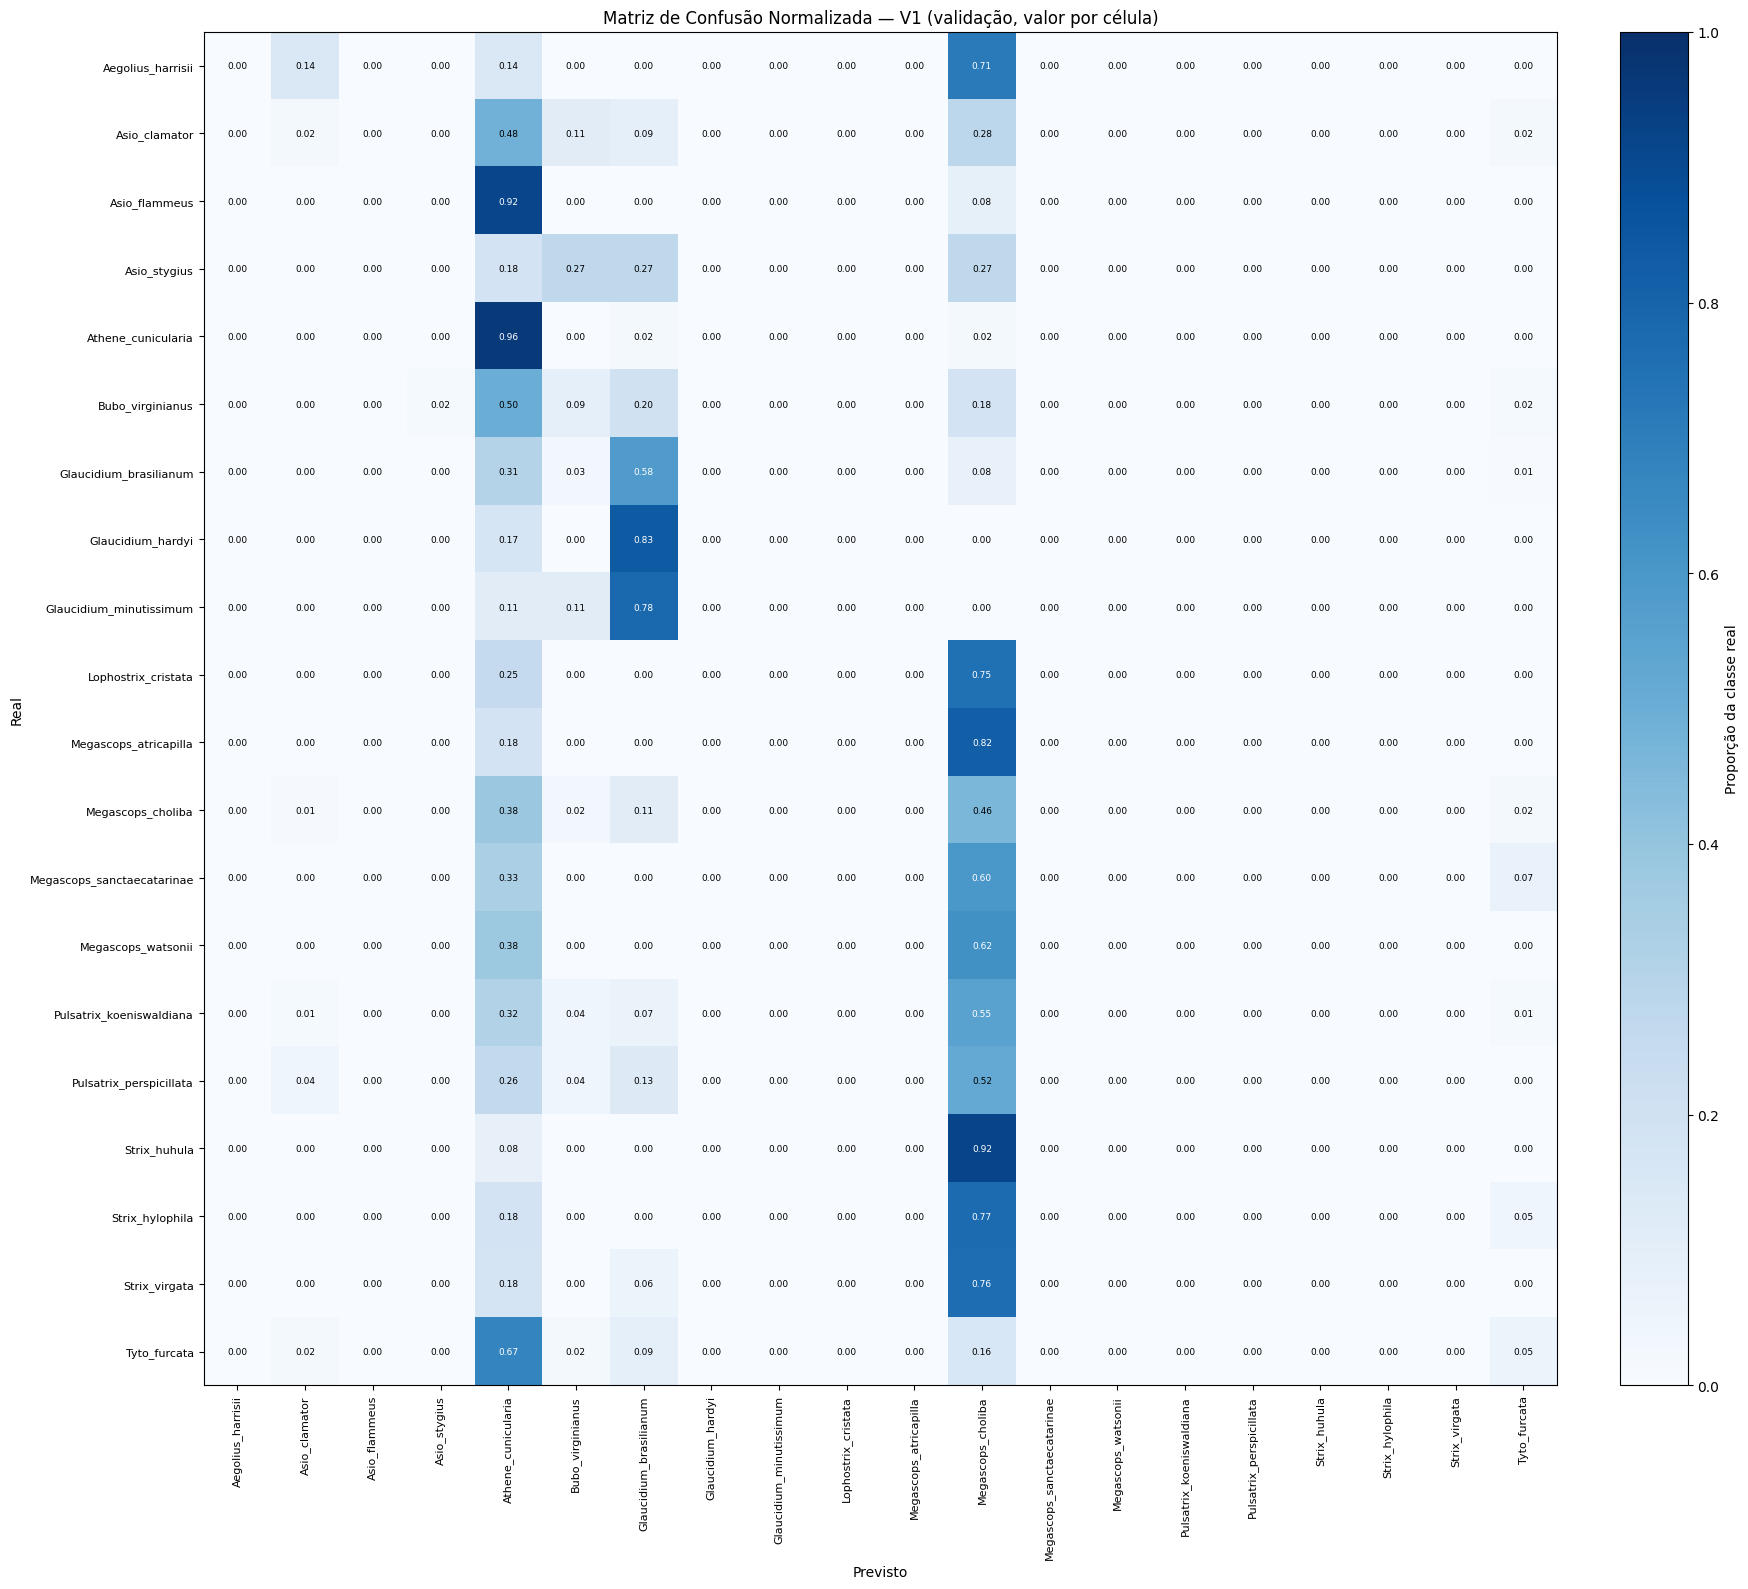

Parâmetros da V1: 12,941,012
Tamanho aproximado dos pesos: 49.37 MB

Observação: a V1 usa divisão 80/20 e não possui conjunto de teste separado.
Estas métricas são de validação; para comparação direta com V2–V5 seria necessário re-treinar com 70/15/15.


,V1 (validação)
loss_val,1.308900e+00
acuracia,6.249000e-01
acuracia_balanceada,1.081000e-01
precisao_macro,1.034000e-01
recall_macro,1.081000e-01
f1_macro,9.550000e-02
top3,7.712000e-01
parametros,1.294101e+07
tamanho_mb,4.936600e+01


In [11]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, classification_report, confusion_matrix
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

num_classes = len(nomes_das_classes)

print("Avaliação da V1 no conjunto de validação (split 80/20)...")
perda_val, acuracia_keras = modelo.evaluate(dataset_validacao, verbose=0)
probabilidades = modelo.predict(dataset_validacao, verbose=0)

y_reais = np.concatenate([y for x, y in dataset_validacao], axis=0)
y_previstos = np.argmax(probabilidades, axis=1)

top3 = np.mean(
    np.any(
        np.argsort(probabilidades, axis=1)[:, -3:] == y_reais[:, None],
        axis=1,
    )
)

metricas_v1 = {
    'loss_val': float(perda_val),
    'acuracia': float(accuracy_score(y_reais, y_previstos)),
    'acuracia_balanceada': float(balanced_accuracy_score(y_reais, y_previstos)),
    'precisao_macro': float(precision_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'recall_macro': float(recall_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'f1_macro': float(f1_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'top3': float(top3),
}

print("\nMétricas da V1 na validação:")
for nome, valor in metricas_v1.items():
    print(f"  {nome}: {valor:.4f}")

print("\nRelatório por espécie:")
print(classification_report(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    target_names=nomes_das_classes,
    digits=3,
    zero_division=0,
))

recall_classes = recall_score(
    y_reais, y_previstos, labels=np.arange(num_classes),
    average=None, zero_division=0
)
suporte = np.bincount(y_reais, minlength=num_classes)

tabela_recall = pd.DataFrame({
    'Classe': nomes_das_classes,
    'Suporte': suporte,
    'Recall': recall_classes,
}).sort_values('Recall')

display(tabela_recall.round(3))

sem_recall = tabela_recall.loc[tabela_recall['Recall'] == 0, 'Classe'].tolist()
baixo_recall = tabela_recall.loc[tabela_recall['Recall'] < 0.10, 'Classe'].tolist()
print("Classes com recall zero:", sem_recall if sem_recall else "nenhuma")
print("Classes com recall < 10%:", baixo_recall if baixo_recall else "nenhuma")

cm = confusion_matrix(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    normalize='true',
)

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(nomes_das_classes, rotation=90, fontsize=8)
ax.set_yticklabels(nomes_das_classes, fontsize=8)
ax.set_xlabel('Previsto')
ax.set_ylabel('Real')
ax.set_title('Matriz de Confusão Normalizada — V1 (validação, valor por célula)')

for i in range(num_classes):
    for j in range(num_classes):
        valor = cm[i, j]
        ax.text(
            j, i, f'{valor:.2f}',
            ha='center', va='center', fontsize=6.5,
            color='white' if valor > 0.55 else 'black'
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Proporção da classe real')
plt.tight_layout()
plt.show()

parametros = modelo.count_params()
tamanho_mb = parametros * 4 / (1024 ** 2)
print(f"Parâmetros da V1: {parametros:,}")
print(f"Tamanho aproximado dos pesos: {tamanho_mb:.2f} MB")
print("\nObservação: a V1 usa divisão 80/20 e não possui conjunto de teste separado.")
print("Estas métricas são de validação; para comparação direta com V2–V5 seria necessário re-treinar com 70/15/15.")


resumo_metricas = pd.DataFrame([{
    **(metricas_v1),
    'parametros': parametros,
    'tamanho_mb': tamanho_mb,
}]).T.rename(columns={0: 'V1 (validação)'})
display(resumo_metricas.round(4))


## 7. Conclusão e Aplicações Práticas em Engenharia

A execução deste projeto permitiu validar o ciclo de desenvolvimento iterativo característico da Engenharia de *Software* e Inteligência Artificial. A versão inicial do modelo revelou limitações críticas, como o *overfitting* e a dependência excessiva de uma classe maioritária (*Athene cunicularia*). Contudo, a aplicação de técnicas de regularização — nomeadamente *Data Augmentation* e *Dropout* — provou ser eficaz para estabilizar a aprendizagem e forçar a rede a extrair características espaciais complexas de todas as espécies, em vez de apenas memorizar os dados de treino.

Apesar da melhoria na capacidade de generalização do algoritmo, a matriz de confusão evidenciou que o desbalanceamento da base de dados continua a ser um desafio. O trabalho futuro para otimizar este sistema passaria obrigatoriamente pela recolha de mais amostras fotográficas das espécies minoritárias ou pela aplicação de pesos artificiais às classes (*class weights*) durante a compilação.

**Aplicações em Sistemas Reais**
No contexto prático da Engenharia, um modelo de Visão Computacional com esta arquitetura não funciona de forma isolada no ecrã de um computador. A sua verdadeira utilidade surge quando é exportado, quantizado (para reduzir o consumo de memória) e integrado num sistema embarcado (*edge computing*).

Pode projetar-se a implementação deste algoritmo num microcontrolador acoplado a um módulo de câmara (dispositivo IoT). Alojado num invólucro resistente às intempéries, desenhado através de modelação 3D e alimentado por um circuito de regulação de tensão independente, este sistema físico poderia ser instalado em parques ecológicos ou reservas ambientais. O dispositivo operaria de forma autónoma, classificando e catalogando a avifauna local em tempo real, fornecendo dados vitais para a monitorização da biodiversidade de forma completamente não intrusiva.